<div style="width: 100%; text-align: center; display: flex; flex-direction: column; align-items: center; justify-content: center;">

  <h1 style="font-weight: bold; margin: 0; padding: 0;"> <b>Mecánica de Medios Continuos</b></h1>
  
  <h3 style="font-weight: bold; margin-top: 10px; margin-bottom: 5px;">Termalización de un gas de partículas monoatómicas</h3>
  
  <p style="font-style: italic; margin-top: 0; margin-bottom: 20px;">Simulación de dinámica molecular y distribución de Maxwell-Boltzmann</p>
  
  

## Enunciado

**Objetivo**: El objetivo es simular el proceso de *termalización* de un gas de partículas monoatómicas y poner a prueba algunos de los principios básicos de la mecánica estadística.

**Procedimiento**:

Para conseguir el objetivo:

1. Generar posiciones al azar para N partículas puntuales, en una caja rectangular de lado L.

2. Para las velocidades, asignar inicialmente a todas las partículas velocidades al azar pero con la misma magnitud, p.e. $v_{0}$ = 1 (en unidades termodinámicas).

3. Definir un paso de tiempo para realizar la simulación del movimiento de las partículas así:

   - Calcular $L_{mol}$ en la caja.
   - El paso de tiempo será $dt = (L_{mol}/v_0)/f_t$ donde $f_t = 10$. Puede hacer más pequeño o más grande $f_t$ de dependiendo de si la simulación tarda mucho tiempo en ejecutarse.

4. Simular el movimiento de las partículas del gas así:

   - Por cada paso de tiempo modificar la posición de las partículas con la velocidad que cada una tenga en un momento dado.

   - Si una partícula se sale por un lado de la caja la partícula debe volver a la caja por el lado opuesto (condiciones de frontera periódicas).

   - En cada paso de tiempo, y por cada partícula, determinar cuál de las demás partículas de la caja esta más cerca. Si la distancia a la que se encuentra la otra partícula es menor que $L_{mol}/f_d$, donde $f_d=10$ asumiremos que las dos partículas chocan y calcularemos el resultado del choque elástico entre ellas. Puede modificar el parámetro $f_d$ de acuerdo a los resultados.

5. Hacer un histograma de la rapidez de las partículas cada 100 pasos de tiempo y mire como a medida que se producen los choques va cambiando la distribución de velocidades.

6. Cuando la distribución de velocidades tenga la apariencia de una distribución de Maxwell-Boltzmann, decimos que la simulación o el gas, ha termalizado. Determinaremos la temperatura y la presión del gas. La presión no tiene que calcularse usando choques, puede usarse la relación que tiene con la densidad de energía cinética.

**Resultados esperados**:

- Gráficos mínimos:
  - Varios gráficos con distribución de la rapidez de las partículas durante la simulación.

- Datos mínimos:
  - Valor de la temperatura al final de la simulación.
  - Valor de la presión al final de la simulación.

- Gráficos opcionales:
  - Animación del movimiento de las partículas del gas.
  - Evolución de la temperatura como función del tiempo.
  - Evolución de la presión como función del tiempo.


## Solución

## **Librerías**

In [1]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np
import plotly.graph_objects as go

from plotly.subplots import make_subplots
from mpl_toolkits.mplot3d import Axes3D
from scipy.stats import norm

1. Posiciones al azar para N partículas puntuales, en una caja rectangular de lado L.

In [2]:
L = 10
N = 50

#Datos ramdom para las posiciones:
ps = pd.DataFrame(np.random.uniform(0,L,size=(N,3)),columns=['x','y','z'])

ps['r'] = np.sqrt((ps.x)**2+(ps.y)**2 + (ps.z)**2)

# Primeras 5 filas
ps[:5]

,x,y,z,r
0,8.183453,7.270279,8.194332,13.673804
1,6.803926,9.830421,3.392477,12.427368
2,7.730581,6.378416,6.937545,12.189159
3,0.335172,8.211996,9.162630,12.308656
4,8.149623,1.305723,4.352158,9.330731


2. Para las velocidades, asignar inicialmente a todas las partículas velocidades al azar pero con la misma magnitud, p.e. $v_{0}$ = 1 (en unidades termodinámicas).

## Unidades Termodinámicas:

In [3]:
# Constante de Boltzmann:
kB = 1.38e-23 # kg m^2 / (K s^2)

# Masa atómica
UM = 1.66e-27 # kg

# Nanómetro
UL = 1e-9 # m

# Temperatura ambiente
UT = 300 # K

# Unidad de tiempo derivada
Ut = np.sqrt(UM*UL**2/(UT*kB))

# Unidad de velocidad derivada
Uv = UL/Ut
KB = 1

print(f"Unidad de tiempo: {Ut:g} s")
print(f"Unidad de velocidad: {Uv:g} m/s")

URHO = UM/UL**3
UE = UM*Uv**2
UF = UM*UL/Ut**2
UP = UF/UL**2
print(f"Unidad de densidad: {URHO:g} kg/m^3")
print(f"Unidad de energía: {UE:g} J")
print(f"Unidad de fuerza: {UF:g} N")
print(f"Unidad de presión: {UP:g} Pa")

Unidad de tiempo: 6.33219e-13 s
Unidad de velocidad: 1579.23 m/s
Unidad de densidad: 1.66 kg/m^3
Unidad de energía: 4.14e-21 J
Unidad de fuerza: 4.14e-12 N
Unidad de presión: 4.14e+06 Pa


## Velocidad:

In [4]:
# Generar vectores de velocidad:
v = np.random.normal(size=(N, 3))

# Normalizar para que midan 1:
v /= np.linalg.norm(v, axis=1, keepdims=True)

# Asignar al DataFrame:
ps['v0x'] = v[:, 0]
ps['v0y'] = v[:, 1]
ps['v0z'] = v[:, 2]
ps['v0']  = np.linalg.norm(v, axis=1)

# Primeras 5 filas
ps[:5]

,x,y,z,r,v0x,v0y,v0z,v0
0,8.183453,7.270279,8.194332,13.673804,-0.646542,-0.755332,0.107033,1.0
1,6.803926,9.830421,3.392477,12.427368,0.961406,-0.273043,-0.033861,1.0
2,7.730581,6.378416,6.937545,12.189159,-0.643974,-0.604749,-0.468590,1.0
3,0.335172,8.211996,9.162630,12.308656,0.754493,-0.656170,-0.013458,1.0
4,8.149623,1.305723,4.352158,9.330731,0.497520,0.325428,0.804096,1.0


3. Definir un paso de tiempo para realizar la simulación del movimiento de las partículas así:

- Calcular $L_{mol}$ en la caja.


In [5]:
mA = 1 # Unidades termodinámicas
T = 1 # Unidades termodinámicas

# Volumen de la caja
V = L**3

n = N/V
rho = n*mA

print(f"Densidad de número: {n} U.T")
print(f"Densidad de masa: {rho} U.T")

Vmol = mA/rho
Lmol = Vmol**(1/3)
print(f"Volumen por partícula: {Vmol}")
print(f"Distancia media entre partículas: {Lmol}")

Densidad de número: 0.05 U.T
Densidad de masa: 0.05 U.T
Volumen por partícula: 20.0
Distancia media entre partículas: 2.7144176165949063


   - El paso de tiempo será $dt = (L_{mol}/v_0)/f_t$ donde $f_t = 10$. Puede hacer más pequeño o más grande $f_t$ de dependiendo de si la simulación tarda mucho tiempo en ejecutarse.

In [6]:
ft=10
dt = (Lmol)/ft
print(f"Paso del tiempo: {dt} U.T")

Paso del tiempo: 0.27144176165949063 U.T


## Visualización del estado inicial:

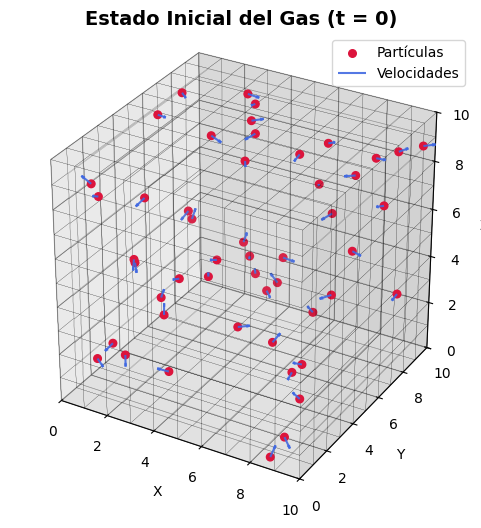

In [7]:
# Definir la caja
axes = [L, L, L]
data = np.ones(axes, dtype=bool) # Usar bool directamente
alpha = 0.10                     # Un poco menos de opacidad para ver mejor el interior


# Colores de la caja (blanco/gris transparente)
colors = np.empty(axes + [4], dtype=np.float32)
colors[:] = [0.8, 0.8, 0.8, alpha]

# Crear la figura
fig = plt.figure(figsize=(6, 6)) # Un poco más grande para que se vea bien
ax = fig.add_subplot(111, projection='3d')

# Dibujar la caja
ax.voxels(data, facecolors=colors, edgecolors='k', linewidth=0.1)

# Dibujar las partículas (esferas rojas)
# Usamos s=30 para que los puntos no se vean como un polvo diminuto
ax.scatter(ps.x, ps.y, ps.z, color='crimson', s=30, alpha=1.0, label='Partículas')

# Dibujar los vectores de velocidad
# Multiplicamos la velocidad por 0.5 solo para que la flecha se vea un poco más larga visualmente
escala_flecha = 0.9
ax.quiver(ps.x, ps.y, ps.z,
          ps.v0x * escala_flecha, ps.v0y * escala_flecha, ps.v0z * escala_flecha,
          color='royalblue', alpha=0.9, length=0.5, normalize=False, label='Velocidades')

# Estética de los ejes
ax.set_xlim(0, L)
ax.set_ylim(0, L)
ax.set_zlim(0, L)
ax.set_xlabel('X')
ax.set_ylabel('Y')
ax.set_zlabel('Z')
ax.set_title('Estado Inicial del Gas (t = 0)', fontsize=14, fontweight='bold')

# hacer que los ejes se vean más como una caja real
ax.set_box_aspect([1,1,1])

plt.legend(loc='upper right')
plt.show()

4. Simular el movimiento de las partículas:

- Por cada paso de tiempo modificar la posición de las partículas con la velocidad que cada una tenga en un momento dado.

   


Ecuación de movimiento:

$$
\vec{r}_{\text{nuevo}} = \vec{r}_{\text{viejo}} + \vec{v} \cdot dt
$$

Donde:

*   $\vec{r}$ es el vector posición $(x, y, z)$.
*   $\vec{v}$ es el vector velocidad $(v_x, v_y, v_z)$.
*   $dt$ es el paso de tiempo.

In [8]:
# Extraemos las posiciones como una matriz de (N filas, 3 columnas)
pos = np.array([ps.x, ps.y, ps.z]).T

# Extraemos las velocidades como una matriz de (N filas, 3 columnas)
vel = np.array([ps.v0x, ps.v0y, ps.v0z]).T

# Actualizamos TODAS las posiciones a la vez (esto es magia de NumPy)
pos = pos + vel * dt

# Primeros 5 instantes
pos[:5]

array([[8.00795397, 7.06525002, 8.22338525],
       [7.06489135, 9.75630557, 3.38328569],
       [7.55577923, 6.21426203, 6.81035052],
       [0.53997282, 8.03388427, 9.15897727],
       [8.28467063, 1.39405757, 4.57042307]])

## FRONTERAS PERIÓDICAS
Si una partícula se sale por un lado de la caja la partícula debe volver a la caja por el lado opuesto.

   

In [9]:
# Si una partícula se sale de [0, L], el operador módulo (%)
# la hace reaparecer por el lado opuesto automáticamente.
pos = pos % L

ps['x'] = pos[:, 0]
ps['y'] = pos[:, 1]
ps['z'] = pos[:, 2]

# Primeras 5 filas
ps[['x', 'y', 'z']][:5]

,x,y,z
0,8.007954,7.065250,8.223385
1,7.064891,9.756306,3.383286
2,7.555779,6.214262,6.810351
3,0.539973,8.033884,9.158977
4,8.284671,1.394058,4.570423


Para que el gas termalice, las partículas deben intercambiar energía mediante colisiones. En cada paso de tiempo evaluamos la distancia entre todos los pares de partículas.

### Detección de colisión
Consideremos dos partículas $i$ y $j$ con posiciones $\vec{r}_i$ y $\vec{r}_j$. La distancia entre ellas es:

$$
d_{ij} = \|\vec{r}_i - \vec{r}_j\|
$$

Si $d_{ij} < \frac{L_{mol}}{f_d}$ (donde $f_d = 10$), asumimos que han chocado.


 $$
 \Delta x = \Delta x - L \cdot \text{round}\left(\frac{\Delta x}{L}\right)
 $$
 Y análogamente para $y$ y $z$.

### Choque elástico (Masas iguales)
Para partículas de la misma masa, la conservación del momento y la energía resulta en un intercambio de las componentes de la velocidad a lo largo de la línea que une sus centros. Sea $\hat{n}$ el vector unitario:

$$
\hat{n} = \frac{\vec{r}_i - \vec{r}_j}{\|\vec{r}_i - \vec{r}_j\|}
$$

La velocidad de cada partícula se actualiza así:

$$
\vec{v}_i^{\text{nuevo}} = \vec{v}_i - (\vec{v}_i \cdot \hat{n} - \vec{v}_j \cdot \hat{n})\hat{n}
$$

$$
\vec{v}_j^{\text{nuevo}} = \vec{v}_j - (\vec{v}_j \cdot \hat{n} - \vec{v}_i \cdot \hat{n})\hat{n}
$$

In [10]:
np.random.seed(42)  # Semilla para reproducibilidad
v0      = 1.0       # Rapidez inicial
fd     = 10        # Factor de distancia de colisión
pasos   = 1500      # Número total de pasos

# Derivados
L_mol   = L / N**(1/3)         # Distancia media interpartícula
dt      = (L_mol / v0) / ft   # Paso de tiempo
radio_colision = L_mol / fd   # Radio de colisión

print(f"Longitud molecular L_mol = {L_mol:.4f}")
print(f"Paso de tiempo dt = {dt:.4f}")
print(f"Radio de colisión = {radio_colision:.4f}")

Longitud molecular L_mol = 2.7144
Paso de tiempo dt = 0.2714
Radio de colisión = 0.2714


In [11]:
historial_rapideces = []
historial_tiempos = []

print("🚀 Iniciando simulación...")

for step in range(pasos):

    # --- 4.1 Mover posiciones ---
    pos = pos + vel * dt
    pos = pos % L  # Fronteras periódicas

    # --- 4.2 Detección de colisiones ---
    for i in range(N):
        for j in range(i + 1, N):

            # Distancia con convención de mínima imagen
            r_ij = pos[i] - pos[j]
            r_ij = r_ij - L * np.round(r_ij / L)
            dist = np.linalg.norm(r_ij)

            if dist < radio_colision and dist > 0:
                n = r_ij / dist
                v_i_n = np.dot(vel[i], n)
                v_j_n = np.dot(vel[j], n)

                # Choque elástico (intercambio de componentes normales)
                vel[i] = vel[i] - (v_i_n - v_j_n) * n
                vel[j] = vel[j] - (v_j_n - v_i_n) * n

    # --- 5. Guardar datos cada 100 pasos ---
    if step % 100 == 0:
        rapideces_actuales = np.linalg.norm(vel, axis=1)
        historial_rapideces.append(rapideces_actuales.copy())
        historial_tiempos.append(step * dt)

print("✅ Simulación terminada con éxito.")

🚀 Iniciando simulación...
✅ Simulación terminada con éxito.


5. Hacer un histograma de la rapidez de las partículas cada 100 pasos de tiempo
y mire como a medida que se producen los choques va cambiando la distribución de velocidades.



## Distribución de rapideces y Maxwell-Boltzmann

A medida que las partículas colisionan, la energía cinética se redistribuye entre todas ellas. Según la mecánica estadística, un gas en equilibrio térmico alcanza la **distribución de Maxwell-Boltzmann** para sus rapideces.

La probabilidad de encontrar una partícula con rapidez $v$ (en 3D) está dada por:

$$
f(v) = 4\pi \left( \frac{m}{2\pi k_B T} \right)^{3/2} v^2 e^{-\frac{mv^2}{2k_B T}}
$$

Para observar cómo el gas se termaliza, guardaremos la rapidez de todas las partículas cada cierta cantidad de pasos (por ejemplo, cada 100) y haremos un histograma. Veremos cómo la distribución inicial (donde todas las partículas tienen la misma rapidez $v_0$) se "aplana" y se ensancha hasta coincidir con la curva teórica de Maxwell-Boltzmann.

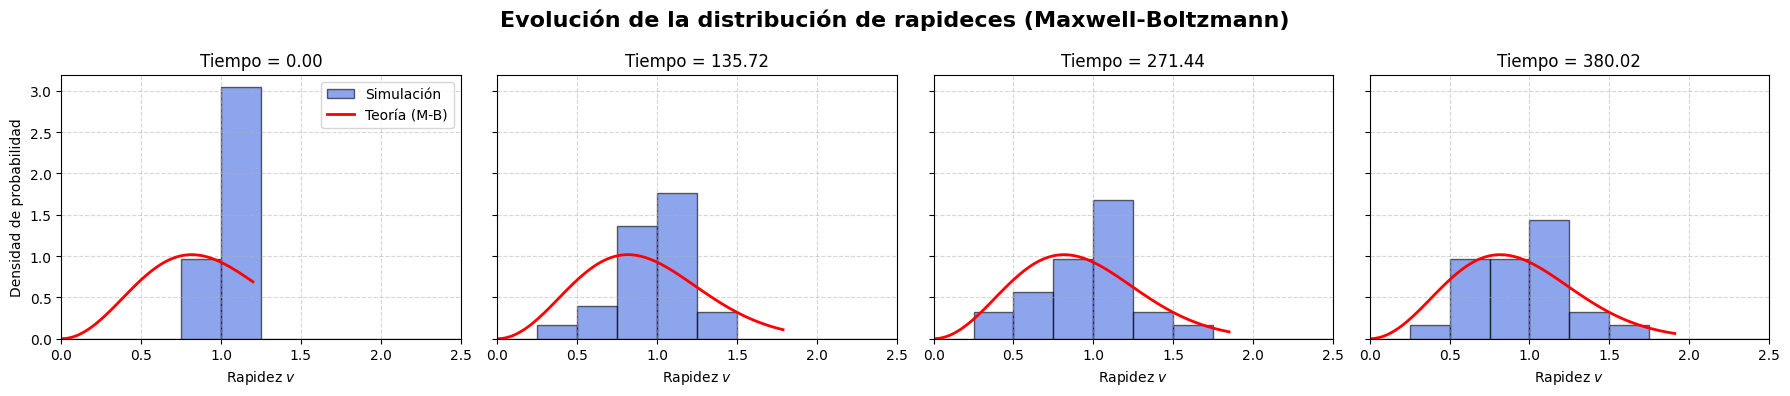

In [12]:
# Vamos a graficar 4 momentos clave: Inicio, 1/3, 2/3 y Final

n_guardados = len(historial_rapideces)
indices = [0, n_guardados // 3, 2 * n_guardados // 3, n_guardados - 1]

fig, axes = plt.subplots(1, 4, figsize=(18, 4), sharey=True)
fig.suptitle('Evolución de la distribución de rapideces (Maxwell-Boltzmann)', fontsize=16, fontweight='bold')

for ax, idx in zip(axes, indices):
    v = historial_rapideces[idx]
    t = historial_tiempos[idx]

    # Histograma de los datos simulados
    ax.hist(v, bins=20, range=(0, 5), density=True, alpha=0.6, color='royalblue', edgecolor='black', label='Simulación')

    # Curva teórica de Maxwell-Boltzmann (asumiendo k_B=1, m=1)
    # La temperatura T se puede estimar a partir de la energía cinética media: <E> = 3/2 T
    T_estimada = np.mean(v**2) / 3.0
    v_teorico = np.linspace(0, max(v)*1.2, 100)
    f_teorico = 4 * np.pi * (1 / (2 * np.pi * T_estimada))**(3/2) * v_teorico**2 * np.exp(-v_teorico**2 / (2 * T_estimada))

    ax.plot(v_teorico, f_teorico, 'r-', linewidth=2, label='Teoría (M-B)')

    ax.set_title(f'Tiempo = {t:.2f}')
    ax.set_xlabel('Rapidez $v$')
    ax.set_xlim(0, max(2.5, np.max(v) * 1.2))

    if ax == axes[0]:
        ax.set_ylabel('Densidad de probabilidad')
    ax.grid(True, linestyle='--', alpha=0.5)
    if idx == indices[0]:
        ax.legend()

plt.tight_layout()
plt.show()

6.
## Temperatura y Presión del gas termalizado

Cuando la distribución de rapideces se ajusta a la curva de Maxwell-Boltzmann, decimos que el gas ha alcanzado el **equilibrio térmico**. Podemos determinar sus propiedades macroscópicas:

### Temperatura
Del teorema de equipartición de la energía, la energía cinética media por partícula está relacionada con la temperatura:

$$
\langle E_k \rangle = \frac{1}{2} \langle v^2 \rangle = \frac{3}{2} k_B T
$$

Por lo tanto:
$$
T = \frac{\langle v^2 \rangle}{3 k_B}
$$
*(En nuestras unidades, $k_B = 1$ y $m = 1$)*.

### Presión
Usando la relación de la densidad de energía cinética para un gas ideal:
$$
P = \frac{2}{3} \frac{E_k}{V} = \frac{2}{3} \frac{N \langle E_k \rangle}{L^3}
$$
Donde $V = L^3$ es el volumen de la caja y $N$ es el número de partículas.

In [13]:
# Extraer las velocidades del último instante guardado (gas termalizado)
vel_final = historial_rapideces[-1] # Esto son las rapideces (v), no las componentes
v2_media = np.mean(vel_final**2)    # <v^2>

# Calcular Temperatura (usando k_B = 1, m = 1)
T_final = v2_media / 3.0

# Calcular Energía Cinética Total
# E_k_total = N * <E_k> = N * (1/2 * <v^2>)
E_k_total = N * (0.5 * v2_media)

# Calcular Presión
V_caja = L**3
P_final = (2.0 / 3.0) * (E_k_total / V_caja)

print("="*40)
print("🎯 RESULTADOS FINALES DEL GAS")
print("="*40)
print(f"Temperatura final (T) : {T_final:.4f}")
print(f"Presión final (P)     : {P_final:.4f}")
print(f"Energía cinética media: {0.5 * v2_media:.4f} por partícula")
print(f"Volumen de la caja (V): {V_caja:.4f}")
print("="*40)

🎯 RESULTADOS FINALES DEL GAS
Temperatura final (T) : 0.3333
Presión final (P)     : 0.0167
Energía cinética media: 0.5000 por partícula
Volumen de la caja (V): 1000.0000


## Animación

In [14]:
# GENERAR LOS DATOS DE LA ANIMACIÓN

pos_anim = np.random.uniform(0, L, size=(N, 3))
vel_anim = np.random.normal(size=(N, 3))
vel_anim /= np.linalg.norm(vel_anim, axis=1, keepdims=True)
vel_anim *= v0
vel_anim += np.random.normal(0, 0.01, size=(N, 3))

# Guardamos los datos cada 100 pasos

saltos_guardado = 100
frames_totales = 150

frames_pos = []
frames_hist_y = []
frames_curva_y = []
tiempos_frames = []

print("Generando datos...")

# bins (0 a 2.5)
bins = np.linspace(0, 2.5, 21)
bin_centers = (bins[:-1] + bins[1:]) / 2
ancho_bin = bins[1] - bins[0]
v_teorico = np.linspace(0, 2.5, 100)

paso_actual = 0

for frame in range(frames_totales):
    # --- SIMULACIÓN FÍSICA (Avanzamos 100 pasos) ---
    for _ in range(saltos_guardado):
        pos_anim = pos_anim + vel_anim * dt
        pos_anim = pos_anim % L

        for i in range(N):
            for j in range(i + 1, N):
                r_ij = pos_anim[i] - pos_anim[j]
                r_ij = r_ij - L * np.round(r_ij / L)
                dist = np.linalg.norm(r_ij)
                if dist < radio_colision and dist > 0:
                    n = r_ij / dist
                    v_i_n = np.dot(vel_anim[i], n)
                    v_j_n = np.dot(vel_anim[j], n)
                    vel_anim[i] = vel_anim[i] - (v_i_n - v_j_n) * n
                    vel_anim[j] = vel_anim[j] - (v_j_n - v_i_n) * n

    paso_actual += saltos_guardado

    # --- GUARDAR ESTADO ---
    frames_pos.append(pos_anim.copy())
    tiempos_frames.append(paso_actual * dt) # Guardamos el tiempo real

    rapideces = np.linalg.norm(vel_anim, axis=1)
    counts, _ = np.histogram(rapideces, bins=bins)

    alturas_norm = (counts / N) / ancho_bin
    frames_hist_y.append(alturas_norm)

    T_estimada = np.mean(rapideces**2) / 3.0
    if T_estimada > 0.01:
        f_teorico = 4 * np.pi * (1 / (2 * np.pi * T_estimada))**(3/2) * v_teorico**2 * np.exp(-v_teorico**2 / (2 * T_estimada))
    else:
        f_teorico = np.zeros_like(v_teorico)
    frames_curva_y.append(f_teorico)

print(f"Se generaron {len(frames_pos)} frames. Tiempo final: {tiempos_frames[-1]:.2f}")

# CREAR LA FIGURA

fig = make_subplots(
    rows=1, cols=2,
    specs=[[{'type': 'scene'}, {'type': 'xy'}]],
    subplot_titles=("Gas 3D", "Distribución de Rapideces"),
    column_widths=[0.5, 0.5]
)

trace_3d = go.Scatter3d(
    x=frames_pos[0][:, 0], y=frames_pos[0][:, 1], z=frames_pos[0][:, 2],
    mode='markers', marker=dict(size=5, color='crimson', opacity=0.9),
    name='Partículas'
)

trace_hist = go.Bar(
    x=bin_centers, y=frames_hist_y[0],
    width=ancho_bin,
    marker=dict(color='royalblue', line=dict(color='black', width=0.5)),
    opacity=0.7, name='Simulación'
)

trace_curva = go.Scatter(
    x=v_teorico, y=frames_curva_y[0],
    mode='lines', line=dict(color='red', width=3), name='Teoría M-B'
)

fig.add_trace(trace_3d, row=1, col=1)
fig.add_trace(trace_hist, row=1, col=2)
fig.add_trace(trace_curva, row=1, col=2)


# CREAR FRAMES (CON TIEMPO EN EL TÍTULO)

frames = []
for i in range(frames_totales):
    # Añadimos el tiempo al nombre del frame para que se vea en el slider/título
    frames.append(go.Frame(
        data=[
            go.Scatter3d(x=frames_pos[i][:, 0], y=frames_pos[i][:, 1], z=frames_pos[i][:, 2]),
            go.Bar(x=bin_centers, y=frames_hist_y[i], width=ancho_bin),
            go.Scatter(y=frames_curva_y[i])
        ],
        name=f"{tiempos_frames[i]:.2f}" # Guardamos el tiempo
    ))

fig.frames = frames


# LAYOUT

fig.update_layout(
    title="Termalización de un Gas",
    width=1000, height=500,
    scene=dict(
        xaxis=dict(range=[0, L]), yaxis=dict(range=[0, L]), zaxis=dict(range=[0, L]),
        aspectmode='cube'
    ),
    xaxis=dict(range=[0, 2.5], title='Rapidez v'),
    yaxis=dict(range=[0, 2.6], title='Densidad de probabilidad'),

    updatemenus=[dict(
        type="buttons",
        buttons=[
            dict(label="▶ Play", method="animate",
                 args=[None, dict(frame=dict(duration=300, redraw=True), transition=dict(duration=0))]),
            dict(label="⏸ Pause", method="animate",
                 args=[[None], dict(frame=dict(duration=0, redraw=False), mode="immediate")])
        ],
        direction="left", pad={"r": 10, "t": 70}, showactive=False, x=0.05, y=1.15
    )],
    # Añadimos un slider para ver el tiempo exacto
    sliders=[dict(
        steps=[
            dict(method="animate",
                 args=[[f"frame_{i}"], dict(mode="immediate", frame=dict(duration=300, redraw=True))],
                 label=f"{tiempos_frames[i]:.0f}") for i in range(frames_totales)
        ],
        currentvalue=dict(prefix="Tiempo: "),
        len=0.9, x=0.05, y=0, xanchor="left", yanchor="bottom"
    )]
)

fig.show()

Generando datos...
Se generaron 150 frames. Tiempo final: 4071.63
